In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os
os.chdir("/content/drive/MyDrive/simuteh-2330511067/notebook")
print(os.getcwd())
print(os.listdir(".."))

/content/drive/MyDrive/simuteh-2330511067/notebook
['data', 'notebook', 'src', 'hasil', 'laporan', 'requirements.txt', '.git', 'README.md', '.gitignore']


In [ ]:
import os, sys
print("folder kerja :", os.getcwd())
print("isi ../src   :", os.listdir("../src") if os.path.exists("../src") else "TIDAK ADA")
print("sys.path     :", [p for p in sys.path if "src" in p])

folder kerja : /content/drive/MyDrive/simuteh-2330511067/notebook
isi ../src   : ['utils_cv.py', 'buat_dataset_sintetis.py', '__pycache__', 'praproses.py', 'utils_tepi.py', 'praproses_acuan.py']
sys.path     : ['../src', '../src']


In [ ]:
import os, sys, importlib
sys.path = [p for p in sys.path if p != "../src"]   # buang entri relatif yang bermasalah
sys.path.insert(0, "/content/drive/MyDrive/simuteh-2330511067/src")
importlib.invalidate_caches()
sys.path_importer_cache.pop("../src", None)

from praproses import simpan_param
simpan_param({})
print(os.listdir("../hasil"))

['b1_bgr_rgb.png', '.gitkeep', 'b1_pipeline.png', 'b1_tabel_risiko.csv', 'b3_histogram_ringan.png', 'b3_histogram_5kondisi.png', 'b3_clahe_V_vs_BGR.png', 'b3_perbaikan_gelap.png', 'b3_perbaikan_terang.png', 'b3_perbaikan_kontras_rendah.png', 'b3_perbaikan_bayangan.png', 'b4_tabel_penapis.csv', 'b4_di_vs_kernel.png', 'b4_grafik_psnr.png', 'b4_grafik_waktu.png', 'b4_crop_bercak.png', 'b4_psnr_12_normal.csv', 'b5_uji_bercak_palsu.csv', 'b5_panel_sehat.png', 'b5_uji_mitigasi_ringkas.csv', 'b5_uji_mitigasi_kb.csv', 'b5_uji_mitigasi_sehat.csv', 'b5_tradeoff_mitigasi.png', 'b5_tabel12_final.csv', 'b5_uji_bercak_palsu_final.csv', 'b5_panel_sehat_final.png', 'param_praproses.json', 'b5_crop_bercak.png', 'b5_pipeline_final.png', 'b2_kb_kanal.csv', 'b2_kb_kanal_ringan.csv', 'b2_kanal_terbaik.png']


Langkah 1.2 Persiapan dan gradien Sobel. Jalankan kode berikut. Kode 1.2 menghitung
gradien dengan kernel manual lalu memeriksanya terhadap cv2.Sobel.


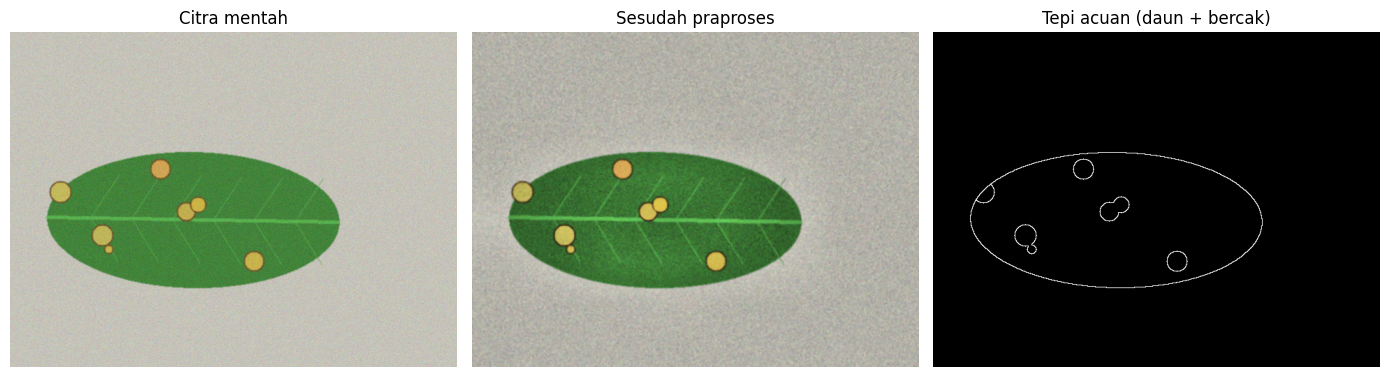

In [ ]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json")) # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")
def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb
img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])
plt.savefig("../hasil/p5_setup.png", dpi=150, bbox_inches="tight")

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 645.8


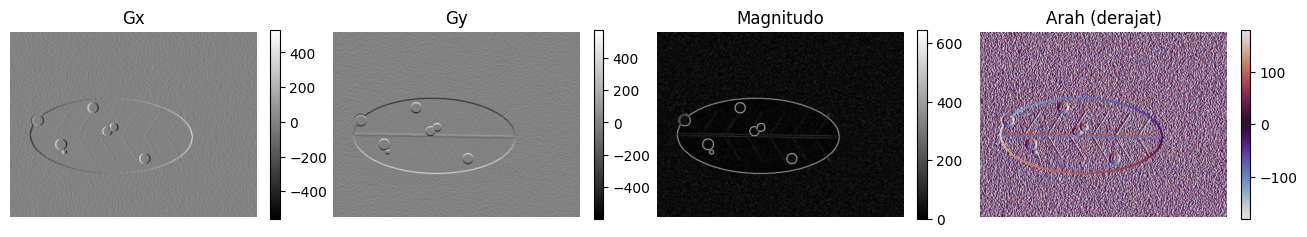

In [ ]:
g = pra[:, :, 2].astype(np.float32) # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx) # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky) # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))
# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))
plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
    plt.savefig("../hasil/p5_gradien.png", dpi=150, bbox_inches="tight")


Langkah 1.3 Empat operator pada satu citra. Fungsi-fungsi berikut dipakai lagi pada
langkah berikutnya, jadi jalankan seluruhnya. Contoh hasil yang diharapkan tampak pada
Gambar 2.

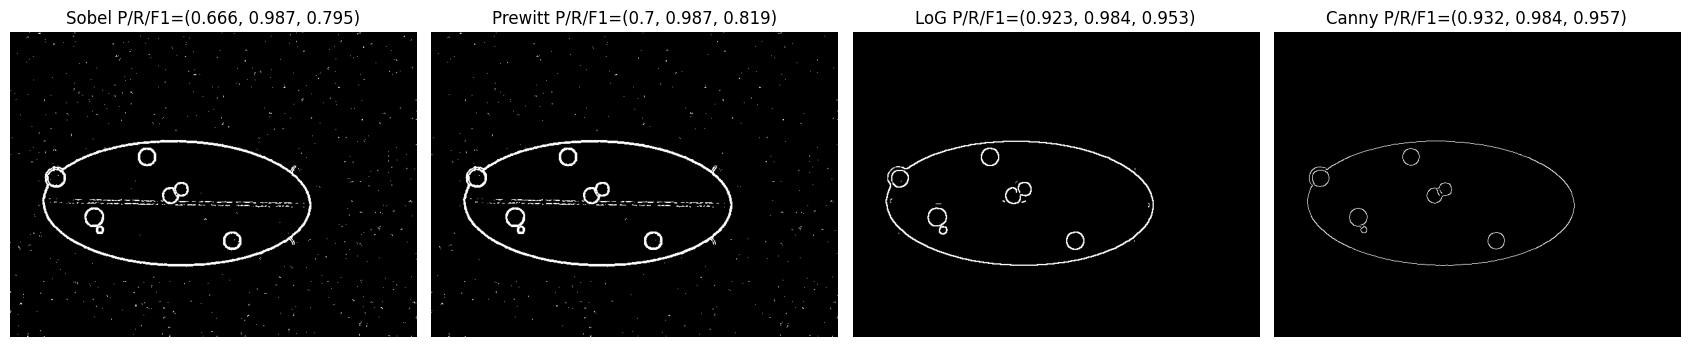

In [ ]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()),
       [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))
plt.savefig("../hasil/p5_panel_operator.png", dpi=150, bbox_inches="tight")

Langkah 1.4 Perbandingan menyeluruh. Bandingkan keempat operator pada 40 citra
berbercak, untuk citra mentah dan sesudah praproses serta kanal Gray dan R. Salin rerata
F1 ke laporan dengan format Tabel 6

In [ ]:
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))

    for sumber, im in [
        ("mentah", img),
        ("praproses", praproses(img, PARAM))
    ]:
        for kanal, g in [
            ("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)),
            ("R", im[:, :, 2])
        ]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)

                baris.append([
                    d.kondisi_cahaya,
                    sumber,
                    kanal,
                    nm,
                    p,
                    r,
                    f1
                ])

tabel_tepi = pd.DataFrame(
    baris,
    columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"]
)

ringkas = (
    tabel_tepi
    .groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]]
    .mean()
    .round(3)
)

print(ringkas)

tabel_tepi.to_csv(
    "../hasil/p5_tabel_tepi.csv",
    index=False
)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.763  0.757  0.758
                LoG      0.636  0.997  0.770
                Prewitt  0.825  0.966  0.880
                Sobel    0.799  0.973  0.866
          R     Canny    0.990  0.984  0.987
                LoG      0.923  0.997  0.955
                Prewitt  0.633  0.997  0.730
                Sobel    0.567  0.997  0.673
praproses Gray  Canny    0.684  0.959  0.792
                LoG      0.532  0.998  0.682
                Prewitt  0.582  0.998  0.724
                Sobel    0.552  0.998  0.696
          R     Canny    0.958  0.993  0.974
                LoG      0.843  0.998  0.901
                Prewitt  0.513  0.998  0.636
                Sobel    0.466  0.998  0.593


1.5


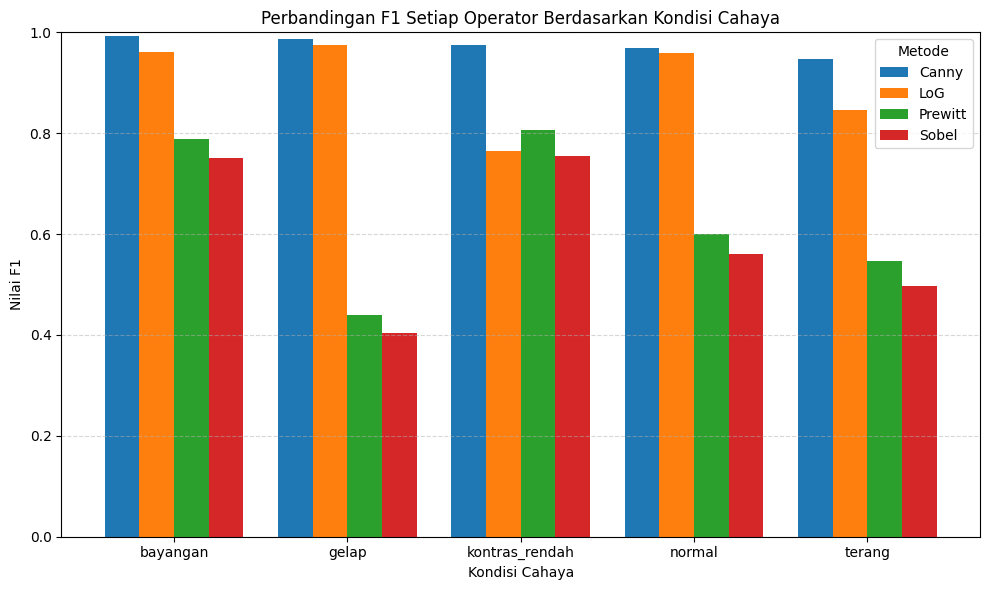

Grafik berhasil disimpan: hasil/p5_f1_kondisi.png


In [ ]:
# Kode 1.5 Grafik F1 per Kondisi Cahaya

# Ambil data kanal R setelah praproses
data_f1 = tabel_tepi[
    (tabel_tepi["sumber"] == "praproses") &
    (tabel_tepi["kanal"] == "R")
]

# Hitung rata-rata F1 berdasarkan kondisi cahaya dan metode
grafik_f1 = data_f1.pivot_table(
    index="kondisi",
    columns="metode",
    values="F1",
    aggfunc="mean"
)

# Buat grafik batang
ax = grafik_f1.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Perbandingan F1 Setiap Operator Berdasarkan Kondisi Cahaya")
plt.xlabel("Kondisi Cahaya")
plt.ylabel("Nilai F1")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metode")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Simpan grafik
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=300, bbox_inches="tight")

plt.show()

print("Grafik berhasil disimpan: hasil/p5_f1_kondisi.png")

Langkah 2.2 Pengaruh sigma dan ambang

In [ ]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]  # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.584  0.996  0.672     0.977
      30/90    0.020  0.998  0.039     0.992
      50/150   0.144  0.997  0.218     0.982
1.0   100/200  0.982  0.996  0.989     0.975
      30/90    0.281  0.996  0.388     0.980
      50/150   0.865  0.996  0.912     0.976
2.0   100/200  0.795  0.792  0.794     0.731
      30/90    0.958  0.993  0.974     0.958
      50/150   0.989  0.986  0.987     0.909
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.982   0.972
      30/90    0.992   0.992
      50/150   0.986   0.979
1.0   100/200  0.980   0.971
      30/90    0.983   0.978
      50/150   0.981   0.971
2.0   100/200  0.774   0.688
      30/90    0.969   0.948
      50/150   0.936   0.882


Langkah 2.3 Ambang otomatis


In [ ]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.663  0.547           0.875   0.724   0.823
      tetap 30/90     0.788  0.756           0.916   0.746   0.755
R     otomatis        0.629  0.416           0.902   0.812   0.866
      tetap 30/90     0.993  0.986           0.974   0.968   0.948
kanal  kondisi       
Gray   bayangan          119.4
       gelap             134.8
       kontras_rendah    152.4
       normal            170.1
       terang            193.6
R      bayangan          125.0
       gelap             149.5
       kontras_rendah    154.2
       normal            180.9
       terang            197.1
Name: median, dtype: float64


In [ ]:
2.4 perbaiki ambang otomatis

In [ ]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    h = cv2.GaussianBlur(g, (0, 0), sigma)          # 1. haluskan (tetap uint8)
    hf = h.astype(np.float32)                        # versi float untuk Sobel
    mag = np.hypot(cv2.Sobel(hf, cv2.CV_32F, 1, 0),
                   cv2.Sobel(hf, cv2.CV_32F, 0, 1))  # 2. magnitudo gradien
    atas = np.percentile(mag, q)                     # 3. ambang atas = persentil ke-q
    bawah = rasio * atas                             #    ambang bawah = rasio x atas
    return cv2.Canny(h, bawah, atas)                 # 4. Canny pada citra uint8

In [ ]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for q in [90, 95, 98]:
            baris.append([d.kondisi_cahaya, kanal, q, skor_tepi(canny_persentil(g, q), ac)[2]])
pers = pd.DataFrame(baris, columns=["kondisi", "kanal", "q", "F1"])
print(pers.pivot_table(index=["kanal", "q"], columns="kondisi", values="F1").round(3))

kondisi   bayangan  gelap  kontras_rendah  normal  terang
kanal q                                                  
Gray  90     0.064  0.058           0.057   0.062   0.057
      95     0.291  0.244           0.144   0.368   0.210
      98     0.751  0.754           0.740   0.748   0.754
R     90     0.067  0.059           0.058   0.066   0.059
      95     0.195  0.092           0.119   0.287   0.217
      98     0.944  0.990           0.866   0.991   0.896


Langkah 2.5 Tepi pada daun sehat

kanal            Gray      R
kondisi                     
bayangan        714.5    0.0
gelap           858.2    0.0
kontras_rendah  210.8    0.0
normal          941.8   17.0
terang          951.0  566.5


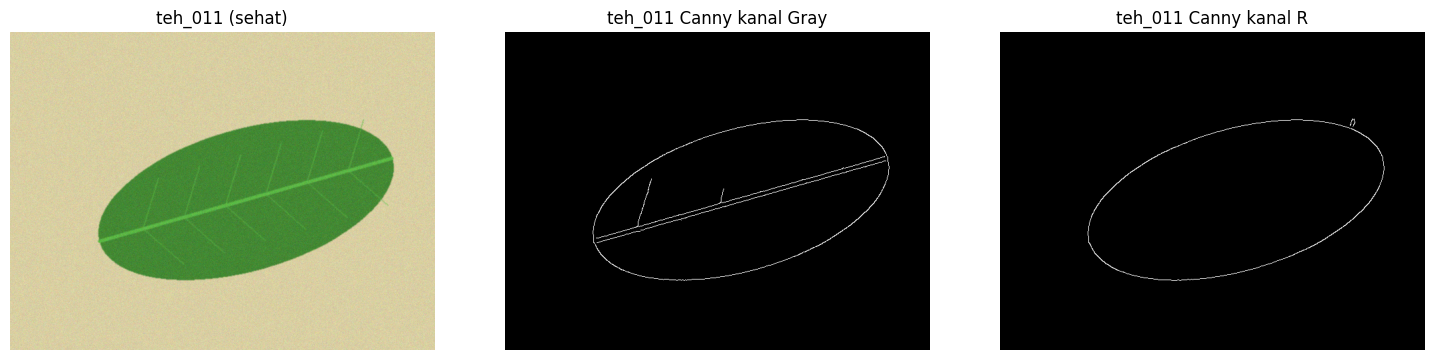

In [ ]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0  # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))
plt.savefig("../hasil/p5_tepi_sehat.png", dpi=150, bbox_inches="tight")

In [37]:
from google.colab import drive
drive.mount("/content/drive")
import os
os.chdir("/content/drive/MyDrive/simuteh-2330511067/notebook")
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/simuteh-2330511067/notebook


In [38]:
print(os.listdir("."))

['P5_tepi.ipynb', 'B3_histogram.ipynb', 'B1_lingkungan.ipynb', 'B4_penapisan.ipynb', 'B5_praproses.ipynb', 'B2_citra_warna.ipynb']
